# **04_Engineering: Ingeniería de Características**

**Objetivo:** Al finalizar este notebook, se habrán aplicado las siguientes técnicas de ingeniería de características al dataset transformado de ofertas laborales de Talento Perú (resultado del notebook 03), con el fin de identificar oportunidades para estudiantes universitarios.

**Criterio de construcción.** Cada variable se somete a la misma secuencia:

1. *Qué información ya existe* en las columnas originales (a veces escondida en un texto).
2. *Por qué* la nueva variable es útil para el análisis.
3. *Cómo* se construye (reglas explícitas y editables).
4. *Aporte*: una tabla o gráfico que demuestra qué permite ver que antes no se veía.


La limpieza, la separación de `ubicacion` en `departamento` y `distrito`, la conversión de fechas y la eliminación de columnas ya se hicieron en los notebooks 02 y 03. Aquí solo se **agregan** columnas derivadas; ninguna columna original se modifica ni se elimina. Cada decisión queda registrada en `04_engineering.csv`.



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

df = pd.read_csv(
    "talento_peru_transformado.csv",
    parse_dates=["fecha_inicio_publicacion", "fecha_fin_publicacion"]
)

In [5]:
df.head()

,id_oferta_hash,puesto,entidad,numero_convocatoria,vacantes,remuneracion_pen,fecha_inicio_publicacion,fecha_fin_publicacion,departamento,distrito
0,1af30dbb2f0f39e7d0c908cf,ESPECIALISTA LEGAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,5670.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO
1,febb4d4b3da59b587a74d154,ASISTENTE LEGAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,4000.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO
2,dcde0256d3fc65eed01f4f18,ASISTENTE ADMINISTRATIVO I MODULO,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,3470.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO
3,071f69f755f06197f36254e3,SERVICIO DE MEDICINA FISICA Y REHABILITACION,UNIDAD EJECUTORA 409: HOSPITAL ALFREDO CALLO R...,D.LEG 1057 - DETERMINADO (SUPLENCIA)-09,1,2900.0,2026-09-18,2026-10-01,CUSCO,SICUANI
4,a7db633abc6875fdc6efb41c,PILOTO DE AMBULANCIA,UNIDAD EJECUTORA 409: HOSPITAL ALFREDO CALLO R...,D.LEG 1057 - DETERMINADO (SUPLENCIA)-09,1,1800.0,2026-09-18,2026-10-01,CUSCO,SICUANI


In [6]:
df.isnull().sum()

,0
id_oferta_hash,0
puesto,0
entidad,0
numero_convocatoria,0
vacantes,0
remuneracion_pen,0
fecha_inicio_publicacion,0
fecha_fin_publicacion,0
departamento,0
distrito,0


In [7]:
df.dtypes

,0
id_oferta_hash,object
puesto,object
entidad,object
numero_convocatoria,object
vacantes,int64
remuneracion_pen,float64
fecha_inicio_publicacion,datetime64[ns]
fecha_fin_publicacion,datetime64[ns]
departamento,object
distrito,object


El dataset no tiene valores nulos y las fechas ya son `datetime`. Las columnas de texto (`puesto`, `entidad`, `numero_convocatoria`) tienen muchos valores distintos.

### Transformación de características

Las variables numéricas del dataset son `remuneracion_pen` y `vacantes`. Se revisa su distribución para decidir si necesitan una transformación. El sesgo (`skew`) mide la asimetría: cerca de 0 es simétrica y valores altos indican cola larga a la derecha.

In [9]:
df[["remuneracion_pen", "vacantes"]].skew()

,0
remuneracion_pen,0.922769
vacantes,12.478839


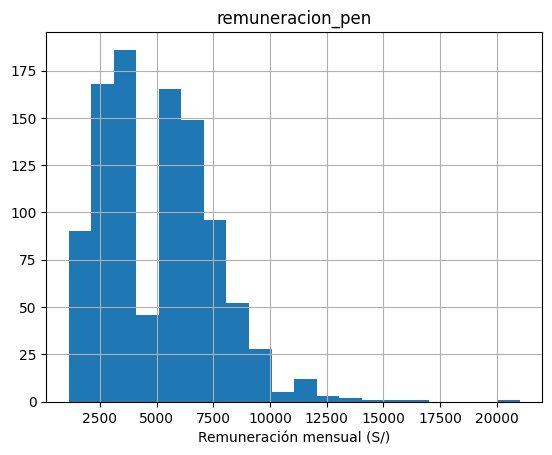

In [10]:
df["remuneracion_pen"].hist(bins=20)
plt.title("remuneracion_pen")
plt.xlabel("Remuneración mensual (S/)")
plt.show()

La remuneración tiene un sesgo moderado a la derecha (≈ 0,92). Se prueba la raíz cuadrada.

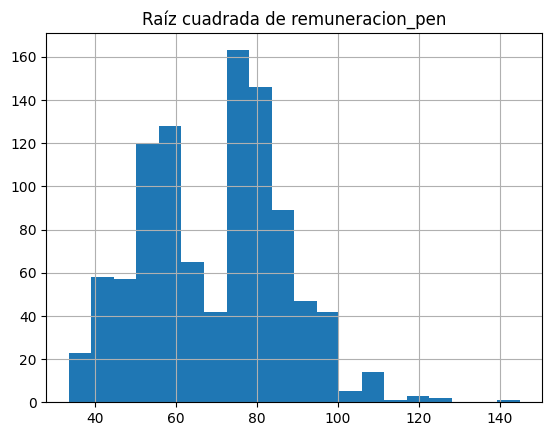

Sesgo tras la raíz cuadrada: 0.22


In [11]:
remuneracion_raiz = np.sqrt(df["remuneracion_pen"])
remuneracion_raiz.hist(bins=20)
plt.title("Raíz cuadrada de remuneracion_pen")
plt.show()
print("Sesgo tras la raíz cuadrada:", round(remuneracion_raiz.skew(), 2))

La raíz cuadrada deja la distribución aproximadamente simétrica (sesgo ≈ 0,22). Sin embargo, la remuneración ya está en soles (unidad interpretable) y su sesgo original es moderado.

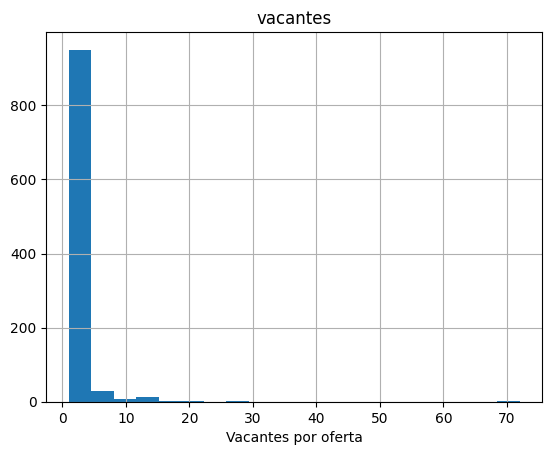

In [12]:
df["vacantes"].hist(bins=20)
plt.title("vacantes")
plt.xlabel("Vacantes por oferta")
plt.show()

`vacantes` tiene un sesgo extremo a la derecha: la gran mayoría de ofertas tiene 1 vacante y unas pocas llegan a decenas (máximo 72). Se comparan la raíz cuadrada y el logaritmo. A diferencia de variables que pueden valer 0, aquí `vacantes ≥ 1`, por lo que el logaritmo está definido sin sumar constantes.

In [13]:
vacantes_raiz = np.sqrt(df["vacantes"])
vacantes_log = np.log(df["vacantes"])

sesgos = pd.Series({"original": df["vacantes"].skew(), "raíz cuadrada": vacantes_raiz.skew(), "logaritmo": vacantes_log.skew()})
sesgos.round(2).to_frame("sesgo")

,sesgo
original,12.48
raíz cuadrada,5.00
logaritmo,2.85


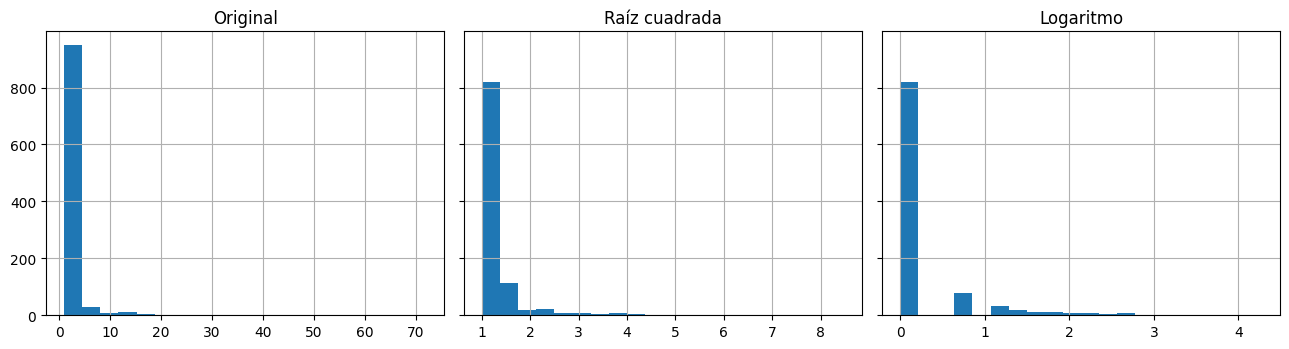

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for eje, serie, titulo in zip(ejes, [df["vacantes"], vacantes_raiz, vacantes_log], ["Original", "Raíz cuadrada", "Logaritmo"]):
    serie.hist(bins=20, ax=eje)
    eje.set_title(titulo)
plt.tight_layout()
plt.show()

El logaritmo reduce el sesgo de ≈ 12,5 a ≈ 2,9, mucho más que la raíz cuadrada (≈ 5,0). No llega a la simetría porque el 81 % de las ofertas tiene exactamente 1 vacante (todas valen 0 tras el logaritmo); por eso más adelante `vacantes` también se discretiza en categorías. Se agrega `vacantes_log` como versión numérica apta para técnicas como PCA.

In [15]:
df["vacantes_log"] = np.log(df["vacantes"])
df[["vacantes", "vacantes_log"]].drop_duplicates().sort_values("vacantes").head(8)

,vacantes,vacantes_log
0,1,0.000000
12,2,0.693147
82,3,1.098612
133,4,1.386294
530,5,1.609438
233,6,1.791759
50,7,1.945910
234,8,2.079442


### Escalamiento de características

`remuneracion_pen` (miles de soles) y `vacantes_log` (0 a 4) están en escalas muy distintas. Las técnicas basadas en distancias o varianzas, como PCA, se dominarían por la variable de mayor escala. Se prueban dos escaladores; los resultados se guardan en DataFrames separados para que `df` conserve las unidades originales, que son las interpretables.

In [16]:
df_num = df[["remuneracion_pen", "vacantes_log"]]
df_num.describe()

,remuneracion_pen,vacantes_log
count,1006.000000,1006.000000
mean,5150.336451,0.239435
std,2487.670062,0.584342
min,1126.700000,0.000000
25%,3103.250000,0.000000
50%,5364.190000,0.000000
75%,6500.000000,0.000000
max,21000.000000,4.276666


Reescalamos o normalizar lass variables numéricas (remuneracion_pen y vacantes_log) para que todos sus valores queden atrapados en un rango exacto entre 0 y 1.

In [17]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_num_MinMax = scaler.fit_transform(df_num)
df_num_MinMax = pd.DataFrame(df_num_MinMax, columns=df_num.columns)
df_num_MinMax

,remuneracion_pen,vacantes_log
0,0.228613,0.000000
1,0.144581,0.000000
2,0.117912,0.000000
3,0.089230,0.000000
4,0.033880,0.000000
...,...,...
1001,0.220059,0.617083
1002,0.220059,0.376330
1003,0.094262,0.000000
1004,0.320697,0.000000


In [18]:
df_num_MinMax.describe()

,remuneracion_pen,vacantes_log
count,1006.000000,1006.000000
mean,0.202464,0.055986
std,0.125176,0.136635
min,0.000000,0.000000
25%,0.099458,0.000000
50%,0.213225,0.000000
75%,0.270378,0.000000
max,1.000000,1.000000


Estandarizamos lass variables restándoles su promedio (media) y dividiéndolas entre su desviación estándar. El resultado es que los datos se centran alrededor de 0, con una desviación estándar de 1.

In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_num_SS = scaler.fit_transform(df_num)
df_num_SS = pd.DataFrame(df_num_SS, columns=df_num.columns)
df_num_SS

,remuneracion_pen,vacantes_log
0,0.209000,-0.409956
1,-0.462645,-0.409956
2,-0.675802,-0.409956
3,-0.905046,-0.409956
4,-1.347447,-0.409956
...,...,...
1001,0.140629,4.108579
1002,0.140629,2.345688
1003,-0.864828,-0.409956
1004,0.944994,-0.409956


In [20]:
df_num_SS.describe()

,remuneracion_pen,vacantes_log
count,1.006000e+03,1.006000e+03
mean,1.271349e-16,2.825220e-17
std,1.000497e+00,1.000497e+00
min,-1.618236e+00,-4.099559e-01
25%,-8.233024e-01,-4.099559e-01
50%,8.600816e-02,-4.099559e-01
75%,5.428111e-01,-4.099559e-01
max,6.374457e+00,6.912456e+00


Como PCA trabaja con varianzas, más adelante se usa `StandardScaler`. El escalado no se guarda en `df`.

### Generación de características

**Generación de características: discretización (binning)**

`remuneracion_pen` es continua con picos muy marcados (5.500, 6.500, 7.500… por escalas salariales). Agruparla en tramos ordenados permite comparar perfiles de oferta y comunicar resultados ("ofertas de nivel medio-alto") sin depender de valores exactos. Los bordes (2.500, 4.000, 6.000, 8.000) se eligieron a partir de la distribución y **no coinciden con los picos salariales**, para no partir una misma escala entre dos tramos.

In [21]:
bins = [0, 2500, 4000, 6000, 8000, np.inf]
ORDEN_RANGOS = ["Bajo (< 2,500)", "Medio-bajo (2,500-3,999)", "Medio (4,000-5,999)",
                "Medio-alto (6,000-7,999)", "Alto (>= 8,000)"]

df["rango_salarial"] = pd.cut(df["remuneracion_pen"], bins, labels=ORDEN_RANGOS, right=False, ordered=True)
df[["remuneracion_pen", "rango_salarial"]]

,remuneracion_pen,rango_salarial
0,5670.0,"Medio (4,000-5,999)"
1,4000.0,"Medio (4,000-5,999)"
2,3470.0,"Medio-bajo (2,500-3,999)"
3,2900.0,"Medio-bajo (2,500-3,999)"
4,1800.0,"Bajo (< 2,500)"
...,...,...
1001,5500.0,"Medio (4,000-5,999)"
1002,5500.0,"Medio (4,000-5,999)"
1003,3000.0,"Medio-bajo (2,500-3,999)"
1004,7500.0,"Medio-alto (6,000-7,999)"


Análizamos la distribución salarial de manera ordenada. En lugar de ver números sueltos, un resumen claro de qué porcentaje del total de ofertas se concentra en cada nivel de sueldo (por ejemplo, cuántas ofertas son de rango bajo, medio o alto).

In [22]:
tabla = df["rango_salarial"].value_counts().reindex(ORDEN_RANGOS).to_frame("ofertas")
tabla["% ofertas"] = (tabla["ofertas"] / len(df) * 100).round(1)
tabla

,ofertas,% ofertas
rango_salarial,,
"Bajo (< 2,500)",111,11.0
"Medio-bajo (2,500-3,999)",295,29.3
"Medio (4,000-5,999)",226,22.5
"Medio-alto (6,000-7,999)",259,25.7
"Alto (>= 8,000)",115,11.4


Los picos de la distribución (escalas de pago) quedan dentro de un tramo y ningún tramo es residual (entre 11 % y 29 % de las ofertas): hay grupos con tamaño suficiente para comparar.

`vacantes` también se discretiza: como el logaritmo no basta para corregir la masa de ofertas con 1 vacante, se separan convocatorias individuales (`1 vacante`), pequeñas (`2 a 5`) y masivas (`6 o más`).

In [26]:
ORDEN_VAC = ["1 vacante", "2 a 5 vacantes", "6 o más vacantes"]
df["categoria_vacantes"] = pd.cut(df["vacantes"], bins=[0, 1, 5, np.inf], labels=ORDEN_VAC, ordered=True)
df[["vacantes", "categoria_vacantes"]]

,vacantes,categoria_vacantes
0,1,1 vacante
1,1,1 vacante
2,1,1 vacante
3,1,1 vacante
4,1,1 vacante
...,...,...
1001,14,6 o más vacantes
1002,5,2 a 5 vacantes
1003,1,1 vacante
1004,1,1 vacante


Agrupamos las ofertas por categoría y calcula dos datos: la cantidad de ofertas y el total de vacantes disponibles. Luego, ordena las categorías según una secuencia definida y calcula el porcentaje que representa cada una respecto al total de ofertas y vacantes.

In [27]:
res = df.groupby("categoria_vacantes", observed=True).agg(ofertas=("vacantes", "size"), vacantes=("vacantes", "sum")).reindex(ORDEN_VAC)
res["% ofertas"] = (res["ofertas"] / res["ofertas"].sum() * 100).round(1)
res["% vacantes"] = (res["vacantes"] / res["vacantes"].sum() * 100).round(1)
res

,ofertas,vacantes,% ofertas,% vacantes
categoria_vacantes,,,,
1 vacante,818,818,81.3,46.5
2 a 5 vacantes,143,389,14.2,22.1
6 o más vacantes,45,551,4.5,31.3


las convocatorias de 6 o más vacantes son el 4,5 % de las ofertas pero concentran el 31,3 % de los puestos disponibles.

**Generación de características: extracción desde texto**

Tres columnas de texto esconden información útil pero no se pueden agrupar tal cual. Se revisa su cardinalidad:

In [29]:
df[["puesto", "entidad", "numero_convocatoria"]].nunique().to_frame("valores distintos")

,valores distintos
puesto,838
entidad,113
numero_convocatoria,282


In [30]:
df[["puesto", "entidad", "numero_convocatoria"]].sample(6, random_state=7)

,puesto,entidad,numero_convocatoria
113,SECRETARIO/A JUDICIAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...
793,PERFIL 729-2026 ANALISTA I EN GESTIÓN PRESUPUE...,CONTRALORIA GENERAL DE LA REPUBLICA,728-06
740,PERFIL 651-2026 AUDITOR/A ANALISTA II EN OBRAS...,CONTRALORIA GENERAL DE LA REPUBLICA,728-06
431,ANALISTA EN DIRECCIÓN Y DISEÑO GRÁFICO DE MATE...,BIBLIOTECA NACIONAL DEL PERU,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...
242,ESPECIALISTA I,TRIBUNAL CONSTITUCIONAL,728-10
417,ESPECIALISTA EN GESTIÓN ADMINISTRATIVA,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,D.LEG 1057 - DETERMINADO (SUPLENCIA)-213


Se definen dos funciones auxiliares para las extracciones siguientes: `normalizar` deja el texto en mayúsculas y sin tildes (para que las reglas no dependan de la ortografía del portal) y `clasificar` asigna la **primera** categoría cuyo patrón coincide, por lo que el orden de las reglas define la prioridad.

In [42]:
def normalizar(serie):
    return (serie.str.upper()
                 .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))

def clasificar(serie, reglas, defecto):
    salida = pd.Series(defecto, index=serie.index, dtype="object")
    asignado = pd.Series(False, index=serie.index)
    for categoria, patron in reglas:
        coincide = serie.str.contains(patron, regex=True) & ~asignado
        salida.loc[coincide] = categoria
        asignado |= coincide
    return salida

*numero_convocatoria → `regimen_laboral` y `modalidad_contrato`.* El código incluye el **régimen laboral** (`D.LEG 1057` = CAS, `728-…`, `276-…`, Ley 30220 de docentes), que determina derechos y nivel de pago, y, solo en CAS, la **modalidad** del contrato. Sin dato explícito, la modalidad queda `NO ESPECIFICADA`.

In [36]:
print(df["numero_convocatoria"].unique())

['D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-093'
 'D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-092'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-09'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-9'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-8'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-10'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-152'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-19'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-155'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-040'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-171'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-167'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-122'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-123'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-234'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-136'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-0137'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-126'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-131'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-132'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-135'
 'D.LEG 1057 - DETERMINADO (SUPLENCIA)-134'
 'D.LEG 1057 -

In [40]:
import re


lista_modalidades = (
    df["numero_convocatoria"]
    .str.extract(r'\(([^)]+)\)', expand=False)
    .dropna()
    .unique()
    .tolist()
)

lista_regimenes = (
    df["numero_convocatoria"]
    .str.split(r'\s*-\s*|\s*\(', regex=True)
    .str[0]
    .str.strip()
    .dropna()
    .unique()
    .tolist()
)


In [44]:
conv = df["numero_convocatoria"].str.upper()

df["regimen_laboral"] = clasificar(conv, [(r, rf"^{re.escape(r)}") for r in lista_regimenes if r], "OTRO")

df["modalidad_contrato"] = clasificar(conv, [(m, rf"\b{re.escape(m)}\b") for m in lista_modalidades], "NO ESPECIFICADA")

pd.crosstab(df["regimen_laboral"], df["modalidad_contrato"], margins=True)

modalidad_contrato,NECESIDAD TRANSITORIA,NO ESPECIFICADA,SUPLENCIA,All
regimen_laboral,,,,
276,0,81,0,81
728,0,389,0,389
D.LEG 1057,453,14,64,531
DOCENTES UNIVERSITARIOS LEY 30220,0,5,0,5
All,453,489,64,1006


In [46]:
df.groupby("regimen_laboral")["remuneracion_pen"].agg(["count", "median", "mean", "min", "max"]).round(0)

,count,median,mean,min,max
regimen_laboral,,,,,
276,81,3318.0,3477.0,1381.0,6666.0
728,389,6500.0,6131.0,3000.0,21000.0
D.LEG 1057,531,3800.0,4687.0,1127.0,15600.0
DOCENTES UNIVERSITARIOS LEY 30220,5,5233.0,5175.0,1308.0,8870.0


El régimen separa claramente niveles de pago: 728 concentra las remuneraciones más altas, 276 las más bajas y CAS es el más heterogéneo. Para un estudiante, el régimen es información decisiva (tipo de contrato y beneficios) que estaba enterrada en un código con 282 valores distintos.

*puesto → `puesto_base`.* `puesto` mezcla el cargo con ruido que no es parte del cargo: códigos de perfil de la Contraloría (`PERFIL 741-2026`), aclaraciones entre paréntesis, nombres de lugares tras un guion (`… - HOSPITAL DE APOYO SIHUAS`) y variantes ortográficas. Ese ruido genera falsos positivos en la búsqueda de palabras clave ("APOYO" aparece en un hospital, no en el cargo). Se normaliza el texto; el nivel (I, II, III…) se **conserva** en `puesto_base` y se extrae por separado más abajo.

In [47]:
df["puesto"].head()

,puesto
0,ESPECIALISTA LEGAL
1,ASISTENTE LEGAL
2,ASISTENTE ADMINISTRATIVO I MODULO
3,SERVICIO DE MEDICINA FISICA Y REHABILITACION
4,PILOTO DE AMBULANCIA


In [50]:
puesto_norm = normalizar(df["puesto"])

df["puesto_base"] = (puesto_norm
    .str.replace(r"^PERFIL\s+\d+\s*-\s*\d{4}\s+", "", regex=True)
    .str.replace(r"^UN/A\s+", "", regex=True)
    .str.replace(r"\(.*?\)", "", regex=True)
    .str.replace(r"\s+-\s+.*$", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip())

df[["puesto", "puesto_base"]].sample(8, random_state=3)

,puesto,puesto_base
920,PERFIL 605-2026 AUDITOR/A ANALISTA II EN OBRAS...,AUDITOR/A ANALISTA II EN OBRAS E INFRAESTRUCTURA
636,ASISTENTE ADMINISTRATIVO,ASISTENTE ADMINISTRATIVO
362,OBSTETRA,OBSTETRA
562,AUXILIAR DE ARCHIVO,AUXILIAR DE ARCHIVO
717,ENFERMERA,ENFERMERA
429,ANALISTA EN SEGURIDAD Y SALUD EN EL TRABAJO,ANALISTA EN SEGURIDAD Y SALUD EN EL TRABAJO
767,PERFIL 469-2026 AUDITOR/A ESPECIALISTA I EN IN...,AUDITOR/A ESPECIALISTA I EN INFRAESTRUCTURA SA...
330,SECRETARIO JUDICIAL,SECRETARIO JUDICIAL


La cardinalidad baja de 838 a 614 valores sin perder el cargo, y las reglas siguientes trabajan sobre el cargo y no sobre códigos o lugares.

*puesto_base → `categoria_ocupacional`.* Responde *"¿qué tipo de cargo es?"* y acerca el análisis al perfil de un estudiante o egresado. El orden de las reglas resuelve cargos ambiguos: `MEDICO ESPECIALISTA` es un profesional de la salud antes que un especialista, y `TRABAJADOR SOCIAL` es profesional antes que operativo. Lo que no coincide queda como `OTROS`.

In [48]:
# listas ordenadas de términos clave para cada categoría
jefatura_terms = r"(?:JEFE|JEFA|GERENTE|SUBGERENTE|DIRECTOR|DIRECTORA|COORDINADOR|RESPONSABLE)"
profesional_terms = r"(?:TRABAJADOR(?:/A|A|OR)? SOCIAL|MEDICO|ENFERMERA|ENFERMERO|OBSTETRA|TECNOLOGO|QUIMICO|PSICOLOG[OA]|ODONTOLOG[OA]|NUTRICIONISTA|ABOGAD[OA]|INGENIER[OA]|ECONOMISTA|CONTADOR[A]?|ARQUITECT[OA]|DOCENTE|PROFESIONAL|LICENCIAD[OA]|BIOLOG[OA]|SOCIOLOG[OA]|PERIODISTA|TRADUCTOR|EDUCADOR|DEFENSOR|PERITO|ARQUEOLOG[OA])"
especialista_terms = r"(?:ESPECIALISTA|ANALISTA|AUDITOR|EJECUTIVO|ASESOR|INSPECTOR|SUPERVISOR|PLANIFICADOR|FORMULADOR|EVALUADOR|CONSULTOR|EXPERTO|MODELADOR|RESOLUTOR|FACILITADOR|GESTOR|EJECUTOR)"
tecnico_terms = r"TECNIC[OA]"
auxiliar_terms = r"(?:AUXILIAR|APOYO OPERATIVO|CHOFER|CONDUCTOR|PILOTO|SERENO|VIGILANTE|VIGILANCIA|LIMPIEZA|TRABAJADOR|OPERARIO|GUARDIAN|CONSERJE|MENSAJERO|PEON|OPERADOR|PERSONAL DE SEGURIDAD|MADRE SUSTITUTA|TIA SUSTITUTA|NOTIFICADOR|ARTESANO|PROMOTOR)"
asistente_terms = r"(?:ASISTEN|SECRETARI[AO]|APOYO|DIGITADOR|RECEPCIONISTA|OFICINISTA|ADMINISTRATIV|ADMINISTRADOR|CAJERO|TESORERO|INTEGRADOR)"


In [51]:

df["categoria_ocupacional"] = (
    df["puesto_base"]
    .astype(str)
    .str.upper()
    .str.replace(r"^\s*-\s*", "", regex=True)
    .apply(lambda x:
        "JEFATURA Y COORDINACION" if re.search(r"\b" + jefatura_terms + r"\b", x) else
        "PROFESIONAL" if re.search(r"\b" + profesional_terms + r"\b", x) else
        "ESPECIALISTA / ANALISTA" if re.search(r"\b" + especialista_terms + r"\b", x) else
        "TECNICO" if re.search(r"\b" + tecnico_terms + r"\b", x) else
        "AUXILIAR / OPERATIVO" if re.search(r"\b" + auxiliar_terms + r"\b", x) else
        "ASISTENTE / APOYO ADMINISTRATIVO" if re.search(r"\b" + asistente_terms + r"\b", x) else
        "OTROS"
    )
)

n_ocup = (df["categoria_ocupacional"] != "OTROS").sum()
print(f"Ofertas con categoría específica: {n_ocup} de {len(df)} ({n_ocup / len(df):.1%})")
df[["puesto_base", "categoria_ocupacional"]].sample(8, random_state=5)

Ofertas con categoría específica: 925 de 1006 (91.9%)


,puesto_base,categoria_ocupacional
596,"ESPECIALISTA EN PLANIFICACION, GESTION Y DESAR...",ESPECIALISTA / ANALISTA
865,ANALISTA II LEGAL EN MATERIA PENAL,ESPECIALISTA / ANALISTA
269,INGENIERO IV,PROFESIONAL
344,ASISTENTE DE LABORATORIO DE BIOLOGIA,OTROS
11,ABOGADO I,PROFESIONAL
687,SECRETARIA I,ASISTENTE / APOYO ADMINISTRATIVO
33,JEFE DE LA UNIDAD DE PLANEAMIENTO Y PRESUPUESTO,JEFATURA Y COORDINACION
936,APOYO OPERATIVO/A II EN CONDUCCION VEHICULAR,AUXILIAR / OPERATIVO


In [52]:
df["categoria_ocupacional"].value_counts().to_frame("ofertas")

,ofertas
categoria_ocupacional,
ESPECIALISTA / ANALISTA,547
PROFESIONAL,157
OTROS,81
AUXILIAR / OPERATIVO,81
TECNICO,58
JEFATURA Y COORDINACION,42
ASISTENTE / APOYO ADMINISTRATIVO,40


La categoría ordena el mercado en escalones salariales coherentes: auxiliares y técnicos en lo más bajo, asistentes después, profesionales y especialistas en lo más alto. Convierte 614 títulos normalizados en 7 grupos comparables. `JEFATURA Y COORDINACION` es la más heterogénea (su rango intercuartílico es el más ancho) porque mezcla jefaturas de grandes entidades con coordinaciones de municipalidades pequeñas.

*entidad → `tipo_entidad`.* Hay 113 entidades, casi todas con muy pocas ofertas, y no se pueden comparar una a una. El *tipo* de entidad (salud, educación, gobierno local, justicia…) es la unidad natural para analizar el mercado. La Contraloría se mantiene como categoría propia por su peso (casi un tercio de las ofertas). Las reglas tienen prioridad por orden (p. ej. `GERENCIA REGIONAL DE SALUD` es salud antes que gobierno regional); lo que no coincide es `GOBIERNO NACIONAL` (ministerios y organismos nacionales).

In [56]:
print(df["entidad"].unique())

['PODER JUDICIAL'
 'UNIDAD EJECUTORA 409: HOSPITAL ALFREDO CALLO RODRIGUEZ- SICUANI - CANCHIS'
 'GERENCIA REGIONAL DE EDUCACIÓN' 'DEFENSORIA DEL PUEBLO'
 'UNIDAD DE GESTION EDUCATIVA LOCAL DE UTCUBAMBA - UGEL-UTCUBAMBA'
 'UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICIA DE LIMA'
 'MINIST. DE TRABAJO Y PROMOCION DEL EMPLEO'
 'SUPERINTENDENCIA DE TRANSPORTE TERRESTRE DE PERSONAS, CARGA Y MERCANCIAS - SUTRAN'
 'ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL - OEFA'
 'CONSERVACION DE BOSQUES'
 'SERVICIO NACIONAL FORESTAL Y DE FAUNA SILVESTRE - SERFOR'
 'COMISION PARA LA PROMOCION DE EXPORTACI'
 'CENTRO NACIONAL DE ESTIMACION, PREVENCION Y REDUCCION DEL RIESGO DE DESASTRES (CENEPRED)'
 'UNIDAD DE GESTION EDUCATIVA LOCAL N° 03 UNIDAD EJECUTORA EDUCACION 315: TRUJILLO NOR OESTE'
 'MUNICIPALIDAD DISTRITAL DE INCLAN'
 'UNIDAD DE GESTION EDUCATIVA LOCAL 06' 'MUNICIPALIDAD DISTRITAL DE ATE'
 'INSTITUTO NACIONAL DE INNOVACION AGRARIA'
 'PROGRAMA NACIONAL DE TELECOMUNICACIONES - PRONATEL'
 'SUPER

In [57]:
entidad_norm = normalizar(df["entidad"])

reglas_entidad = [
    ("CONTRALORIA",                    r"CONTRALORIA"),
    ("SALUD",                          r"\bSALUD\b|HOSPITAL|\bUTES\b|\bAIS\b|ESSALUD|MICRORED|DIRESA|SEGURO INTEGRAL"),
    ("EDUCACION",                      r"EDUCA|\bUGEL\b|COLEGIO"),
    ("UNIVERSIDAD",                    r"UNIVERSIDAD"),
    ("GOBIERNO LOCAL",                 r"MUNICIPALIDAD|MUNICIPIO"),
    ("GOBIERNO REGIONAL",              r"GOBIERNO REGIONAL|\bREGION\b|DIRECCION REGIONAL|DIREC\. REGIONAL|GERENCIA REGIONAL"),
    ("JUSTICIA Y MINISTERIO PUBLICO",  r"PODER JUDICIAL|CORTE SUPERIOR|TRIBUNAL|MINISTERIO PUBLICO|JUZGADO"),
]
df["tipo_entidad"] = clasificar(entidad_norm, reglas_entidad, "GOBIERNO NACIONAL")

df[["entidad", "tipo_entidad"]].drop_duplicates().sample(8, random_state=4)

,entidad,tipo_entidad
35,UNIDAD DE GESTION EDUCATIVA LOCAL N° 03 UNIDAD...,EDUCACION
6,GERENCIA REGIONAL DE EDUCACIÓN,EDUCACION
66,UNIDAD DE GESTION EDUCATIVA LOCAL N. 05,EDUCACION
39,MUNICIPALIDAD DISTRITAL DE ATE,GOBIERNO LOCAL
49,SUPERINTENDENCIA NACIONAL DE CONTROL DE SERVIC...,GOBIERNO NACIONAL
137,UNIDAD DE GESTION EDUCATIVA LOCAL 03,EDUCACION
12,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,JUSTICIA Y MINISTERIO PUBLICO
64,PROGRAMA NACIONAL DE INNOVACION PARA LA COMPET...,GOBIERNO NACIONAL


In [58]:
df["tipo_entidad"].value_counts().to_frame("ofertas").assign(**{"% ofertas": lambda t: (t["ofertas"] / len(df) * 100).round(1)})

,ofertas,% ofertas
tipo_entidad,,
CONTRALORIA,301,29.9
GOBIERNO NACIONAL,183,18.2
SALUD,142,14.1
GOBIERNO REGIONAL,129,12.8
JUSTICIA Y MINISTERIO PUBLICO,88,8.7
GOBIERNO LOCAL,86,8.5
EDUCACION,50,5.0
UNIVERSIDAD,27,2.7


Resume 113 entidades en 8 tipos y muestra diferencias claras de pago (la Contraloría, los organismos nacionales y el sistema de justicia arriba; educación y gobierno local abajo).

**Generación de características: agrupación geográfica**

Hay 23 departamentos, varios con 1 a 15 ofertas (Callao tiene 1), por lo que sus porcentajes son inestables. `macrorregion` los agrupa para comparar territorios con muestra suficiente y medir el **centralismo** (cuántas oportunidades hay fuera de Lima). El mapeo departamento → macrorregión (`LIMA-CALLAO`, `NORTE`, `CENTRO`, `SUR`, `ORIENTE`) sigue la agrupación usual de planificación territorial en el Perú; es una convención (algunos departamentos como Ica podrían asignarse de otra forma) y el diccionario es editable.

In [59]:
print(df["departamento"].unique())

['JUNIN' 'CUSCO' 'AREQUIPA' 'APURIMAC' 'AMAZONAS' 'LORETO' 'LIMA'
 'LA LIBERTAD' 'TACNA' 'ANCASH' 'SAN MARTIN' 'PUNO' 'PIURA'
 'MADRE DE DIOS' 'HUANUCO' 'CAJAMARCA' 'AYACUCHO' 'ICA' 'CALLAO' 'PASCO'
 'LAMBAYEQUE' 'HUANCAVELICA' 'MOQUEGUA']


In [60]:
MACRORREGION = {
    "LIMA": "LIMA-CALLAO", "CALLAO": "LIMA-CALLAO",
    "TUMBES": "NORTE", "PIURA": "NORTE", "LAMBAYEQUE": "NORTE", "LA LIBERTAD": "NORTE", "CAJAMARCA": "NORTE", "AMAZONAS": "NORTE",
    "ANCASH": "CENTRO", "HUANUCO": "CENTRO", "PASCO": "CENTRO", "JUNIN": "CENTRO", "HUANCAVELICA": "CENTRO", "AYACUCHO": "CENTRO", "ICA": "CENTRO",
    "AREQUIPA": "SUR", "MOQUEGUA": "SUR", "TACNA": "SUR", "CUSCO": "SUR", "PUNO": "SUR", "APURIMAC": "SUR",
    "LORETO": "ORIENTE", "SAN MARTIN": "ORIENTE", "UCAYALI": "ORIENTE", "MADRE DE DIOS": "ORIENTE",
}
df["macrorregion"] = df["departamento"].str.upper().map(MACRORREGION)

print("Departamentos sin asignar:", df.loc[df["macrorregion"].isna(), "departamento"].unique().tolist())
df[["departamento", "macrorregion"]].drop_duplicates().sort_values("macrorregion").head(10)

Departamentos sin asignar: []


,departamento,macrorregion
0,JUNIN,CENTRO
180,HUANUCO,CENTRO
626,HUANCAVELICA,CENTRO
100,ANCASH,CENTRO
248,ICA,CENTRO
415,PASCO,CENTRO
220,AYACUCHO,CENTRO
12,LIMA,LIMA-CALLAO
330,CALLAO,LIMA-CALLAO
35,LA LIBERTAD,NORTE


Lima-Callao concentra por sí sola cerca de la mitad de las ofertas (y de las vacantes), más que cualquier otra macrorregión. Las demás tienen entre 157 y 198 ofertas, suficientes para comparar; Oriente (40 ofertas) debe leerse con cautela.

### Extracción y selección de características

**Selección: aporte de cada variable.** Para decidir qué variables valen la pena se mide qué proporción de la **varianza de la remuneración** explica cada variable categórica (razón de correlación η², **ajustada por número de categorías** para no premiar a las variables con muchas categorías). Se comparan las variables originales con las nuevas.

Se excluye `rango_salarial` y sus derivadas porque se construyen a partir de la propia remuneración (comparación circular). El resultado es descriptivo: indica asociación, no causalidad.

In [62]:
def eta2_ajustado(y, grupos):
    d = pd.DataFrame({"y": y, "g": grupos}).dropna()
    n, k = len(d), d["g"].nunique()
    g = d.groupby("g", observed=True)["y"]
    ssb = (g.count() * (g.mean() - d["y"].mean()) ** 2).sum()
    sst = ((d["y"] - d["y"].mean()) ** 2).sum()
    eta2 = ssb / sst
    return eta2, 1 - (1 - eta2) * (n - 1) / (n - k), k

In [64]:
y = df["remuneracion_pen"]

candidatas = {
    "original": ["entidad", "numero_convocatoria", "puesto", "departamento"],
    "nueva": ["regimen_laboral", "modalidad_contrato", "categoria_ocupacional",
              "tipo_entidad", "macrorregion", "categoria_vacantes"],
}
filas = []
for origen, columnas in candidatas.items():
    for c in columnas:
        e2, adj, k = eta2_ajustado(y, df[c])
        filas.append({"variable": c, "origen": origen, "categorias": k, "eta2": e2, "eta2_ajustado": adj})

aporte = pd.DataFrame(filas).sort_values("eta2_ajustado")
aporte.sort_values("eta2_ajustado", ascending=False).round(3).reset_index(drop=True)

,variable,origen,categorias,eta2,eta2_ajustado
0,puesto,original,838,0.952,0.710
1,numero_convocatoria,original,282,0.681,0.557
2,entidad,original,113,0.570,0.516
3,tipo_entidad,nueva,8,0.326,0.321
4,categoria_ocupacional,nueva,7,0.305,0.301
5,departamento,original,23,0.220,0.203
6,macrorregion,nueva,5,0.193,0.190
7,regimen_laboral,nueva,4,0.115,0.112
8,modalidad_contrato,nueva,3,0.035,0.033
9,categoria_vacantes,nueva,3,0.002,-0.000


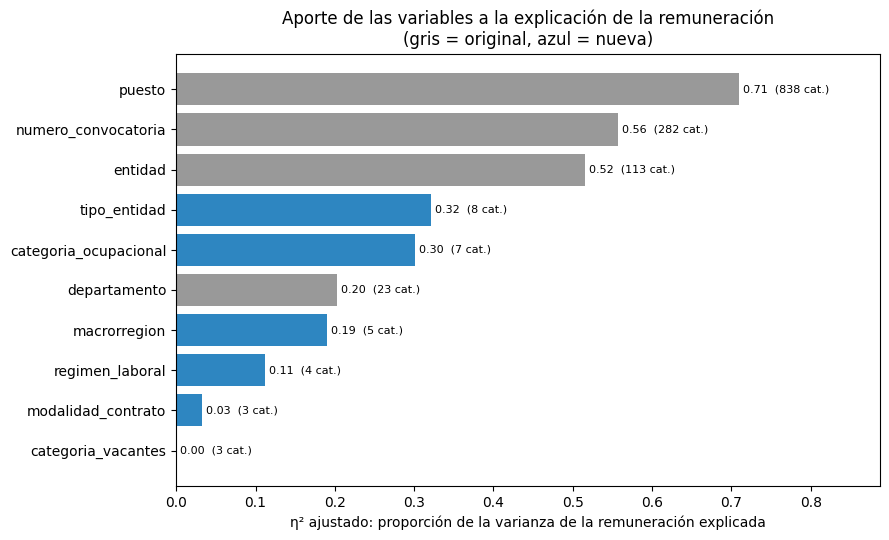

In [65]:
colores = aporte["origen"].map({"original": "#999999", "nueva": "#2e86c1"})
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(aporte["variable"], aporte["eta2_ajustado"].clip(lower=0), color=colores)
for i, (v, k) in enumerate(zip(aporte["eta2_ajustado"].clip(lower=0), aporte["categorias"])):
    ax.text(v + 0.005, i, f"{v:.2f}  ({k} cat.)", va="center", fontsize=8)
ax.set_xlabel("η² ajustado: proporción de la varianza de la remuneración explicada")
ax.set_title("Aporte de las variables a la explicación de la remuneración\n(gris = original, azul = nueva)")
ax.set_xlim(0, max(aporte["eta2_ajustado"].max() * 1.25, 0.1))
plt.tight_layout()
plt.show()

* **Con muy pocas categorías**, `tipo_entidad` y`categoria_ocupacional` explican cerca de un tercio de la variación del pago ($\eta^2$ ajustado = **0,32** y **0,30**). `entidad` llega a **0,52**, pero casi cada entidad es su propia escala y no generaliza. Por su parte, `departamento` alcanza **0,20**, mientras que `macrorregion` recupera casi todo ese poder explicativo con muchas menos categorías, y `regimen_laboral`aporta **0,11**.
* **`puesto`** y **`numero_convocatoria`** obtienen valores muy altos porque prácticamente identifican cada oferta de manera única.
* **`modalidad_contrato`**  y **`categoria_vacantes`** aportan muy poco a la *remuneración*. No se crearon para explicar el pago: describen la estabilidad del contrato y el volumen de puestos, dimensiones que la remuneración no refleja.

### Resumen de variables creadas

In [69]:
guia = [
    "vacantes_log", "rango_salarial", "categoria_vacantes",
    "regimen_laboral", "modalidad_contrato", "puesto_base",
    "categoria_ocupacional", "tipo_entidad", "macrorregion"
]

# Definimos o calculamos las columnas iniciales restando la guía al total actual de columnas
columnas_iniciales = df.shape[1] - len(guia)

resumen = pd.DataFrame({
    "tipo": [str(df[c].dtype) for c in guia],
    "valores_distintos": [df[c].nunique() for c in guia],
}, index=guia)

# Imprimimos el reporte con la sintaxis correcta
print(f"Columnas: {columnas_iniciales} -> {df.shape[1]}  (+{df.shape[1] - columnas_iniciales} guia)")

resumen

Columnas: 10 -> 19  (+9 guia)


,tipo,valores_distintos
vacantes_log,float64,20
rango_salarial,category,5
categoria_vacantes,category,3
regimen_laboral,object,4
modalidad_contrato,object,3
puesto_base,object,614
categoria_ocupacional,object,7
tipo_entidad,object,8
macrorregion,object,5


Se conservan todas las columnas originales y las 1.006 ofertas. `nivel_puesto` es la única variable con nulos, por diseño: un vacío significa que el cargo no informa nivel.

### Guardado y validación

In [74]:
import pandas as pd
from google.colab import files

if 'filas_iniciales' not in locals():
    filas_iniciales = len(df)


assert len(df) == filas_iniciales, "Se alteró el número de filas"
assert df["id_oferta_hash"].is_unique, "Se duplicó algún identificador"
assert df[guia].notna().all().all(), "Hay nulos inesperados en variables nuevas"

archivo_features = "talento_peru_features.csv"

df.to_csv(archivo_features, index=False, encoding="utf-8")

files.download(archivo_features)

print(f"Filas: {filas_iniciales} -> {len(df)} | Columnas: {columnas_iniciales} -> {df.shape[1]}")
print("¡Archivos descargados exitosamente desde Google Colab!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Filas: 1006 -> 1006 | Columnas: 10 -> 19
¡Archivos descargados exitosamente desde Google Colab!
